# ISOLET: spoken-letter self-training

Compare supervised-only training and self-training on a fixed pair of spoken letters. The experiment uses the same random-start protocol, configuration layout, and six trajectory panels as `MNIST.ipynb`.

## Load the official splits

The [UCI ISOLET archive](https://archive.ics.uci.edu/dataset/54/isolet) supplies separate files for training speakers (ISOLET 1–4) and test speakers (ISOLET 5). Its `isolet.info` lists the numeric class codes and counts, with A = 1 through Z = 26, and describes the 617 continuous speech features as already scaled to [−1, 1]. The loader reads and checks those counts. It caches the original archive under `data/isolet/` and uses system `gzip` to decompress the two legacy `.Z` members.

In [ ]:
# Experiment configuration
save_csv = False  # Set to True to export per-iteration measurements.
negative_letter = "B"
positive_letter = "P"
class_proportions = [0.5, 0.2]
labeling_rate = 0.05

n_train = 200
n_test = None  # use all official test rows for the two letters
seeds = [42, 43, 44]

training_steps = 200
eta = 0.05
reg_lambda = 0.1
pi = 5.0
tau = 0.8

In [11]:
from pathlib import Path
import sys

cwd = Path.cwd()
ROOT = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "src" / "algorithms.py").is_file()
     and (path / "experiments" / "__init__.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from within the project checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from experiments.isolet import ISOLETExperiment
from experiments.plotting import experiment_plot_style


experiment = ISOLETExperiment(
    ROOT,
    negative_letter=negative_letter,
    positive_letter=positive_letter,
    class_proportions=class_proportions,
    labeling_rate=labeling_rate,
    n_train=n_train,
    n_test=n_test,
    seeds=seeds,
    training_steps=training_steps,
    eta=eta,
    reg_lambda=reg_lambda,
    pi=pi,
    tau=tau,
)

In [12]:
experiment.load_data()

Official train/test: 6,238 / 1,559 rows, 617 features
B (code 2) → −1; P (code 16) → +1
Cache: /Users/thierryrioual/Desktop/Princeton/Academics/Research/High-dimensional dynamics of ST/implementation/data/isolet/isolet.zip


## Sampling and centering

Encode the negative letter as −1 and the positive letter as +1. For each scenario and seed, sample the training pool without replacement from official ISOLET 1–4, targeting the specified positive proportion $p$. Round each count to the nearest integer, with halves rounded up. Allocate the revealed labels in proportion to the realized training pool.

Use every official ISOLET 5 row for the selected letters by default. Set `n_test` to an integer to subsample that many rows at approximately the available test class balance. The same test rows are used across scenarios within a seed. Center all 617 features by the training pool's mean and apply that mean to its test set. The reported test error is $(1-p)e_-+pe_+$, where $e_-$ and $e_+$ are the test class errors. This gives the target mixture while retaining the available test composition.

## Fitting and diagnostics

Both methods start from the same seeded $w_0\sim\mathcal N(0,I_d)$ and $b_0=0$, using the same initialization convention as MNIST. Record iteration 0 before any updates. The repository learner copies the initial parameters and fits using the same revealed labels, with zero marking unlabeled rows. Use $\pi=0$ for supervised-only training and the configured $\pi$ for self-training.

The six panels use the MNIST diagnostics. The incorrect-and-selected fraction divides the number of wrong selected pseudo-labels by all unlabeled rows. The score gap is half the difference between the positive and negative test class mean scores. For $\pi=0$, selection measures which rows pass the threshold under the supervised model. Hidden labels enter only the post-fit diagnostics.

## Full experiment

Run each scenario for every configured seed. Positive counts and realized fractions are shown as positive / total. Subtract the positive count from the total to obtain the negative count.

In [16]:
runs_by_scenario = experiment.run_comparison()

| Requested p | Seed | Train | Labeled | Unlabeled  | Test |
|---:|---:|---:|---:|---:|---:|
| 0.5 | 42 | 100 / 200 (50.0%) | 5 / 10 (50.0%) | 95 / 190 (50.0%) | 60 / 120 (50.0%) |
| 0.5 | 43 | 100 / 200 (50.0%) | 5 / 10 (50.0%) | 95 / 190 (50.0%) | 60 / 120 (50.0%) |
| 0.5 | 44 | 100 / 200 (50.0%) | 5 / 10 (50.0%) | 95 / 190 (50.0%) | 60 / 120 (50.0%) |
| 0.2 | 42 | 40 / 200 (20.0%) | 2 / 10 (20.0%) | 38 / 190 (20.0%) | 60 / 120 (50.0%) |
| 0.2 | 43 | 40 / 200 (20.0%) | 2 / 10 (20.0%) | 38 / 190 (20.0%) | 60 / 120 (50.0%) |
| 0.2 | 44 | 40 / 200 (20.0%) | 2 / 10 (20.0%) | 38 / 190 (20.0%) | 60 / 120 (50.0%) |

## Trajectories from iteration 0

Each scenario uses the same six-panel layout as MNIST. Lines show seed means and shading shows ± one standard deviation across seeds. The test error panel uses the target-proportion weighting described above.

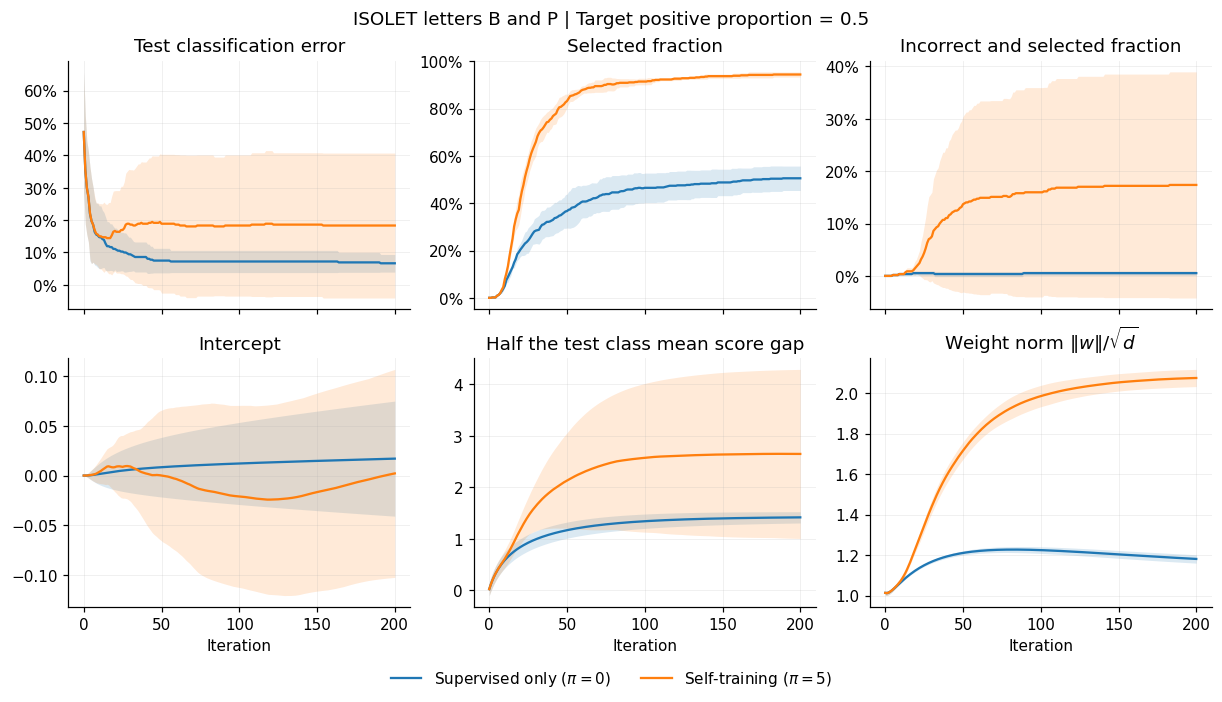

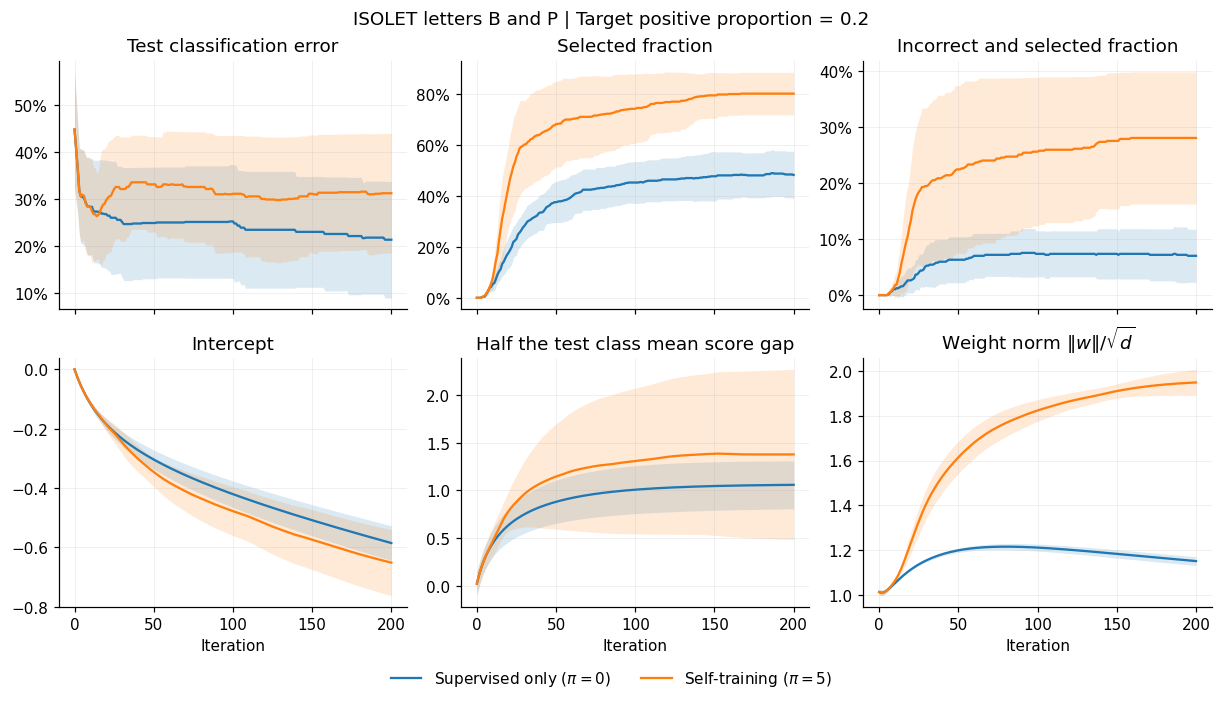

In [17]:
with experiment_plot_style():
    experiment.show_trajectories(runs_by_scenario)

In [18]:
experiment.save_measurements(runs_by_scenario, save_csv=save_csv)

| Requested p | Pseudo-label weight | Initial weighted test error | Final weighted test error | Final selected fraction |
|---:|---:|---:|---:|---:|
| 0.5 | 0 | 47.22% | 6.67% | 50.53% |
| 0.5 | 5 | 47.22% | 18.33% | 94.39% |
| 0.2 | 0 | 44.78% | 21.33% | 48.25% |
| 0.2 | 5 | 44.78% | 31.22% | 80.18% |

Per-iteration measurements saved to /Users/thierryrioual/Desktop/Princeton/Academics/Research/High-dimensional dynamics of ST/implementation/outputs/isolet_self_training/from_scratch_trajectories.csv
